First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset shape:
(1000, 8)

Number of math score values: 1000

IQR METHOD 
Q1: 57.0
Q3: 77.0
IQR: 20.0
Lower limit: 27.0
Upper limi

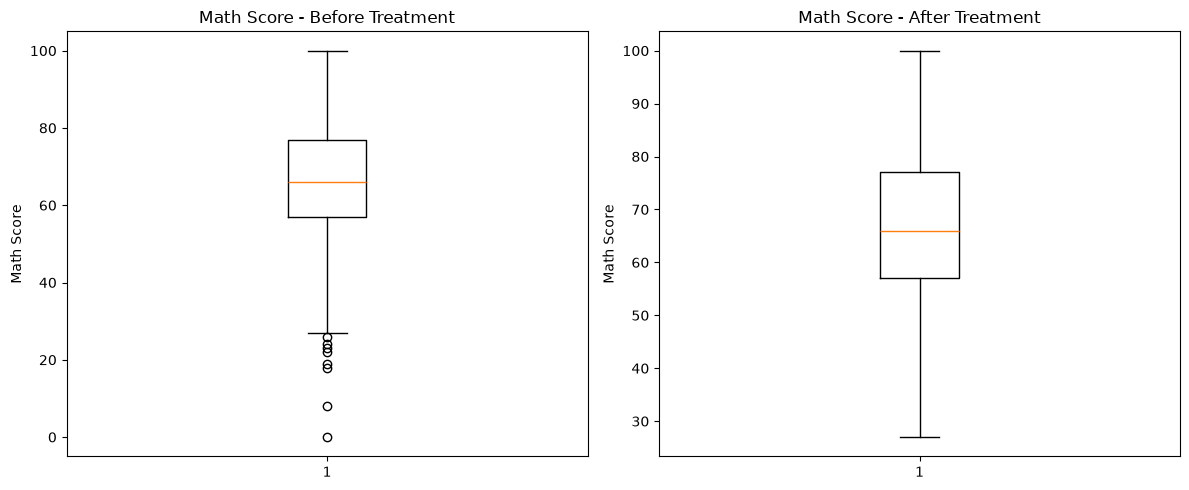

In [27]:


# 1. IMPORT LIBRARIES


import pandas as pd

import matplotlib.pyplot as plt

 

# Read the CSV file

df=pd.read_csv("/Users/spoorthin/Downloads/StudentsPerformance.csv")

 

# Display the first 5 rows

print("First 5 rows of the dataset:")

print(df.head())

 

print("\nDataset shape:")

print(df.shape)

 

# ------------------------------------------------------------

# 3. SELECT THE NUMERICAL COLUMN

# ------------------------------------------------------------

 

data = df["math score"].dropna()

 

print("\nNumber of math score values:", len(data))

 

# ============================================================

# 4. OUTLIER DETECTION USING IQR METHOD

# ============================================================

 

# Calculate Q1 (25th percentile)

Q1 = data.quantile(0.25)

 

# Calculate Q3 (75th percentile)

Q3 = data.quantile(0.75)

 

# Calculate Interquartile Range

IQR = Q3 - Q1

 

# Calculate lower limit

lower_limit = Q1 - 1.5 * IQR

 

# Calculate upper limit

upper_limit = Q3 + 1.5 * IQR

 

print("\nIQR METHOD ")

 

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

 

print("Lower limit:", lower_limit)

print("Upper limit:", upper_limit)

 

# Find IQR outliers

iqr_outliers = df[

    (df["math score"] < lower_limit) |

    (df["math score"] > upper_limit)

]

 

print("Number of IQR outliers:", len(iqr_outliers))

 

# ============================================================

# 5. OUTLIER DETECTION USING Z-SCORE METHOD

# ============================================================

 

# Calculate mean

mean = data.mean()

 

# Calculate standard deviation

std = data.std()

 

# Calculate Z-score for each math score

df["Z_score"] = (df["math score"] - mean) / std

 

# Identify values with absolute Z-score greater than 3

z_outliers = df[abs(df["Z_score"]) > 3]

 

print("\nZ-SCORE METHOD")

print("Mean:", mean)

print("Standard deviation:", std)

print("Number of Z-score outliers:", len(z_outliers))

 

# ============================================================

# 6. DISPLAY THE OUTLIERS

# ============================================================

 

print("\nIQR OUTLIERS")

 

if len(iqr_outliers) > 0:

    print(iqr_outliers[["math score"]])

else:

    print("No IQR outliers found.")

 

print("\n Z-SCORE OUTLIERS ")

 

if len(z_outliers) > 0:

    print(z_outliers[["math score", "Z_score"]])

else:

    print("No Z-score outliers found.")

 

# ============================================================

# 7. OUTLIER TREATMENT

# ============================================================

 

# We use capping based on the IQR limits.

#

# Values below the lower limit are replaced with

# the lower limit.

#

# Values above the upper limit are replaced with

# the upper limit.

 

df["math_score_treated"] = df["math score"].clip(

    lower=lower_limit,

    upper=upper_limit

)

 

print("Treatment method: Capping using IQR limits")

 

# ============================================================

# 8. COMPARE BEFORE AND AFTER TREATMENT

# ============================================================

 

print("\n BEFORE TREATMENT ")

 

print(df["math score"].describe())

 

print("\n AFTER TREATMENT ")

 

print(df["math_score_treated"].describe())

 

# ============================================================

# 9. DISPLAY ORIGINAL AND TREATED VALUES

# ============================================================

 

comparison = df[

    ["math score", "math_score_treated"]

]

 

print(comparison.head(20))

 

# ============================================================

# 10. VISUALIZATION

# ============================================================

 

plt.figure(figsize=(12, 5))

 

# ---------------- BEFORE TREATMENT ----------------

 

plt.subplot(1, 2, 1)

plt.boxplot(df["math score"].dropna())

plt.title("Math Score - Before Treatment")

plt.ylabel("Math Score")

 

# ---------------- AFTER TREATMENT ----------------

 

plt.subplot(1, 2, 2)

plt.boxplot(df["math_score_treated"].dropna())

plt.title("Math Score - After Treatment")

plt.ylabel("Math Score")

 

# Adjust spacing

plt.tight_layout()

 

# Display the plots

plt.show()